# CALCE CX2: Three-model physics-guided benchmarking with Grey Wolf Optimization (GWO)

**Models:** Direct Transformer, Time-Aware Transformer, OLS (CC+CV). Each has an unconstrained control and a *physics-guided* counterpart. GWO searches **loss weights**, while AdamW learns neural-network parameters. For OLS, a constrained/penalized linear regression is used; **OLS is not a PINN**.

**Important scientific qualifications**

- The available CSV does **not** provide electrochemical state equations or complete temperature/current histories. Therefore this is a **soft physics-guided loss**, not a complete PDE PINN.
- The physics priors are: (i) forecasted underlying SOH should usually not *increase* over longer horizons and (ii) predictions should stay within permissive capacity bounds. Measured SOH may exhibit reversible changes or noise. **Weights may correctly optimize to zero.**
- **No inferred rest**: recording gaps longer than the threshold break sequence continuity. No future charging features or target SOH enter predictors.
- **GWO uses validation only**. Report test results once after model selection; do not choose weights from test results. The original/filtered train is used according to the configuration; validation/test remain original.
- The optimization method resembles Wang et al., *An Adaptive-Weight Physics-Informed Neural Network Optimized by Grey Wolf Optimizer for Lithium-Ion Battery State of Health Estimation* (Batteries, 2026, DOI: 10.3390/batteries12040115), but the loss and architecture here are **adaptations, not a reproduction or new discovery**.

### Flow
1. Load five charging features, train-only scaler, contiguous historical windows.
2. Load the previously validation-selected Transformer hyperparameters if a compatible `BEST_MODEL_MANIFEST.json` is present. Otherwise use the documented fallback settings.
3. Train baseline OLS + two baseline Transformers.
4. Run GWO over \(\lambda_{mono},\lambda_{bound}\) for each architecture; candidate neural models receive a short, identical training budget.
5. Train the selected physics-guided models from scratch for three seeds, compare validation and untouched test, export all weights and results.


In [1]:
# Cell 1 — Dependencies (uncomment first line only if missing)
# %pip install torch numpy pandas scipy scikit-learn matplotlib joblib
import os, json, time, copy, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import joblib
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))
print('Device:', DEVICE, 'PyTorch:', torch.__version__)


Device: cuda PyTorch: 2.11.0+cu128


## 1. Reproducible experiment settings

`RUN_MODE='smoke'` verifies the notebook in a few seconds; `quick` runs a small exploratory experiment; `full` performs the full three-seed experiment. Physics weights are **not predetermined as best**: GWO selects them from validation. The previous model's hyperparameters, if saved in a compatible manifest, are reused.

In [2]:
# Cell 2 — Configuration
DEFAULT_DIR = r'C:\Projects\Battery_Soh\pre processed ready to use data'
DATA_DIR = Path(os.environ.get('SOH_DATA_DIR', DEFAULT_DIR))
TRAIN_NAME = 'train_final_filtered.csv'
VAL_NAME, TEST_NAME = 'validation.csv', 'test.csv'
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
HORIZONS = (1, 3, 5)
LOOKBACK = 12
MAX_OBSERVED_GAP_H = 24.0
SEEDS = (42,123,2026)
BATCH_SIZE = 128
MAX_EPOCHS, PATIENCE = 70, 12
RUN_MODE = os.environ.get('SOH_RUN_MODE', 'full')  # 'smoke', 'quick', or 'full'
# This is a soft *apparent-capacity* prior; do not imply that all measured SOH <= 1.
SOH_LOWER, SOH_UPPER = 0.0, 1.10
# Bounds for [lambda_mono, lambda_bound], dimensionless loss coefficients
GWO_LOWER = np.array([0.,0.], dtype=float)
GWO_UPPER = np.array([2.,1.], dtype=float)
DEFAULT_TRANSFORMER_CONFIG = dict(hidden=48,layers=2,heads=4,ff_mult=2,
                                  dropout=0.10,lr=0.001,weight_decay=0.0001)
if RUN_MODE == 'smoke':
    GWO_WOLVES, GWO_ITERS, GWO_EPOCHS = 3, 1, 1
    ACTIVE_SEEDS, ACTIVE_EPOCHS, ACTIVE_PATIENCE = [42], 2, 2
    SMOKE_MAX_WINDOWS = 180
elif RUN_MODE == 'quick':
    GWO_WOLVES, GWO_ITERS, GWO_EPOCHS = 4, 2, 5
    ACTIVE_SEEDS, ACTIVE_EPOCHS, ACTIVE_PATIENCE = [42], 25, 6
    SMOKE_MAX_WINDOWS = None
elif RUN_MODE == 'full':
    GWO_WOLVES, GWO_ITERS, GWO_EPOCHS = 6, 4, 10
    ACTIVE_SEEDS, ACTIVE_EPOCHS, ACTIVE_PATIENCE = list(SEEDS), MAX_EPOCHS, PATIENCE
    SMOKE_MAX_WINDOWS = None
else:
    raise ValueError('Unknown RUN_MODE')
OUT = DATA_DIR / 'gwo_physics_three_models' / RUN_MODE
CHECKPOINTS = OUT / 'checkpoints'
for path in (OUT,CHECKPOINTS): path.mkdir(parents=True,exist_ok=True)
print('Data:', DATA_DIR, '\nOutput:', OUT, '\nMode:', RUN_MODE)


Data: C:\Projects\Battery_Soh\pre processed ready to use data 
Output: C:\Projects\Battery_Soh\pre processed ready to use data\gwo_physics_three_models\full 
Mode: full


In [3]:
# Cell 3 — Reuse previously tuned Transformer configs when compatible
CONFIGS = {'direct_transformer':DEFAULT_TRANSFORMER_CONFIG.copy(),
           'time_transformer':DEFAULT_TRANSFORMER_CONFIG.copy()}
manifest_path = DATA_DIR / 'three_model_final_results' / 'BEST_MODEL_MANIFEST.json'
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    compatible = (manifest.get('features') == FEATURES and
                  manifest.get('lookback') == LOOKBACK and
                  tuple(manifest.get('horizons',())) == HORIZONS)
    if compatible:
        for rec in manifest.get('all_models', []):
            name=rec.get('model')
            if name in CONFIGS and isinstance(rec.get('hyperparameters'),dict):
                old=rec['hyperparameters']
                if all(k in old for k in CONFIGS[name]):
                    CONFIGS[name]={k:old[k] for k in CONFIGS[name]}
        print('Loaded compatible previously selected backbone settings.')
    else:
        print('Previous manifest not compatible; using documented defaults.')
else:
    print('No previous manifest found; using documented defaults (not claimed optimal).')
print(json.dumps(CONFIGS,indent=2))


No previous manifest found; using documented defaults (not claimed optimal).
{
  "direct_transformer": {
    "hidden": 48,
    "layers": 2,
    "heads": 4,
    "ff_mult": 2,
    "dropout": 0.1,
    "lr": 0.001,
    "weight_decay": 0.0001
  },
  "time_transformer": {
    "hidden": 48,
    "layers": 2,
    "heads": 4,
    "ff_mult": 2,
    "dropout": 0.1,
    "lr": 0.001,
    "weight_decay": 0.0001
  }
}


## 2. Leakage-safe dataset construction

Each example uses **only the last 12 observed cycles** to predict three future SOH targets (1, 3, and 5 cycles ahead). This grouped format lets us calculate monotonic-horizon penalties for the **same history**, not arbitrary samples from different batteries. Segments break at missing cycle ordinals, non-positive timestamp differences, or recorded gaps exceeding 24 hours.

In [4]:
# Cell 4 — Load and validate splits
def load_split(name):
    path=DATA_DIR/name
    if not path.exists(): raise FileNotFoundError(f'Missing {path}')
    df=pd.read_csv(path)
    req=['battery','cycle_ordinal','cycle_start','soh']+FEATURES
    missing=[c for c in req if c not in df.columns]
    if missing:raise ValueError(f'{name}: missing columns {missing}')
    df['cycle_start']=pd.to_datetime(df.cycle_start,errors='raise')
    df=df.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)
    if df.duplicated(['battery','cycle_ordinal']).any():
        raise ValueError(f'{name}: duplicate battery/cycle ordinal')
    if df[req].isnull().any().any() or not np.isfinite(df[FEATURES+['soh']].to_numpy(dtype=float)).all():
        raise ValueError(f'{name}: missing or nonfinite data')
    return df
train_df=load_split(TRAIN_NAME)
val_df=load_split(VAL_NAME)
test_df=load_split(TEST_NAME)
sets=[set(d.battery.unique()) for d in (train_df,val_df,test_df)]
assert not (sets[0]&sets[1] or sets[0]&sets[2] or sets[1]&sets[2]), 'Battery leakage'
for split,df in [('train',train_df),('val',val_df),('test',test_df)]:
    print(split,len(df),sorted(df.battery.unique()))
scaler=StandardScaler().fit(train_df[FEATURES])
joblib.dump(scaler,OUT/'feature_scaler.joblib')


train 7690 ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
val 1743 ['CX2_36']
test 1477 ['CX2_38']


['C:\\Projects\\Battery_Soh\\pre processed ready to use data\\gwo_physics_three_models\\full\\feature_scaler.joblib']

In [5]:
# Cell 5 — Contiguous segments, observation windows, and elapsed-time scaling
def segments(frame,minimum=2):
    for battery,g in frame.groupby('battery',sort=True):
        g=g.sort_values('cycle_ordinal').reset_index(drop=True)
        cy_gap=g.cycle_ordinal.diff()
        dt_gap=g.cycle_start.diff().dt.total_seconds().div(3600)
        starts=(cy_gap.ne(1)|dt_gap.le(0)|dt_gap.gt(MAX_OBSERVED_GAP_H)).fillna(True)
        for _,seg in g.groupby(starts.cumsum()):
            if len(seg)>=minimum:
                yield str(battery),seg.reset_index(drop=True)
intervals=[]
for _,s in segments(train_df):
    intervals.extend((s.cycle_start.diff().dt.total_seconds().dropna()/3600).tolist())
DT_SCALE_H=float(np.median(intervals))
assert DT_SCALE_H>0 and np.isfinite(DT_SCALE_H)

class TripleHorizonDataset(Dataset):
    def __init__(self,frame,max_windows=None):
        records=[]
        for battery,s in segments(frame,minimum=LOOKBACK+max(HORIZONS)+1):
            x=scaler.transform(s[FEATURES]).astype('float32')
            y=s.soh.to_numpy('float32')
            cycles=s.cycle_ordinal.to_numpy('int64')
            dt_hours=s.cycle_start.diff().dt.total_seconds().to_numpy()/3600
            dt=np.ones(len(s),dtype='float32')
            dt[1:]=(dt_hours[1:]/DT_SCALE_H).astype('float32')
            for last in range(LOOKBACK-1,len(s)-max(HORIZONS)):
                begin=last-LOOKBACK+1
                w=x[begin:last+1].copy()
                tw=dt[begin:last+1].copy();tw[0]=1.
                yi=np.array([y[last+h] for h in HORIZONS],dtype='float32')
                target_cycles=np.array([cycles[last+h] for h in HORIZONS],dtype='int64')
                records.append((w,tw,yi,battery,int(cycles[last]),target_cycles))
        if max_windows is not None and len(records)>max_windows:
            rng=np.random.default_rng(991)
            idx=np.sort(rng.choice(len(records),max_windows,replace=False))
            records=[records[i] for i in idx]
        self.rows=records
    def __len__(self):return len(self.rows)
    def __getitem__(self,idx):return self.rows[idx]

tr=TripleHorizonDataset(train_df,SMOKE_MAX_WINDOWS)
va=TripleHorizonDataset(val_df,SMOKE_MAX_WINDOWS)
te=TripleHorizonDataset(test_df,SMOKE_MAX_WINDOWS)
assert min(len(tr),len(va),len(te))>0
for ds in (tr,va,te):
    for x,dt,y,battery,last,targets in ds.rows[:100]:
        assert x.shape==(LOOKBACK,5) and dt.shape==(LOOKBACK,) and y.shape==(3,)
        assert np.array_equal(targets-last,np.array(HORIZONS))
print('Triple-horizon windows:',{'train':len(tr),'val':len(va),'test':len(te)},'median dt hours:',DT_SCALE_H)


Triple-horizon windows: {'train': 2678, 'val': 640, 'test': 492} median dt hours: 3.885


## 3. Architecture and physics-guided objectives

Let \(f_\theta(X,h)\) predict SOH from a past-only history \(X\) and requested future horizon \(h\). We evaluate the **three predictions for the same history**:

\[
(p_1,p_3,p_5) = (f_\theta(X,1),f_\theta(X,3),f_\theta(X,5)).
\]

\[
\mathcal L_{data}=\frac{1}{3N}\sum_{i,h}(p_{i,h}-SOH_{i,h})^2
\]

\[
\mathcal L_{mono}=\operatorname{mean}_i\left[\max(0,p_{i,3}-p_{i,1})^2+\max(0,p_{i,5}-p_{i,3})^2\right]
\]

\[
\mathcal L_{bound}=\operatorname{mean}_{i,h}\left[\max(0,-p_{i,h})^2+\max(0,p_{i,h}-1.10)^2\right]
\]

\[
\mathcal L=\mathcal L_{data}+\lambda_{mono}\mathcal L_{mono}+\lambda_{bound}\mathcal L_{bound}.
\]

The **OLS counterpart** uses exactly the same terms and GWO-selected coefficients, but its prediction function remains linear. Positive short-term measured-SOH changes can be real or measurement related, so a strict monotonic model is **not** assumed.

In [6]:
# Cell 6 — Base Transformers: same architectures as the prior optimized notebook
class HorizonHead(nn.Module):
    def __init__(self,hidden):
        super().__init__()
        self.layers=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,1))
    def forward(self,z,h):
        return self.layers(torch.cat([z,h.reshape(-1,1)/max(HORIZONS)],dim=-1)).squeeze(-1)

class SOHTransformer(nn.Module):
    def __init__(self,time_aware,hidden=48,layers=2,heads=4,ff_mult=2,dropout=0.1):
        super().__init__()
        assert hidden%heads==0
        self.time_aware=bool(time_aware)
        self.emb=nn.Linear(len(FEATURES)+int(self.time_aware),hidden)
        self.pos=nn.Parameter(torch.zeros(1,LOOKBACK,hidden))
        enc=nn.TransformerEncoderLayer(d_model=hidden,nhead=heads,
            dim_feedforward=hidden*ff_mult,dropout=dropout,batch_first=True,
            norm_first=True,activation='relu')
        self.encoder=nn.TransformerEncoder(enc,num_layers=layers,enable_nested_tensor=False)
        self.head=HorizonHead(hidden)
    def forward_all(self,x,dt):
        if self.time_aware:
            x=torch.cat([x,torch.log1p(dt.clamp_min(0)).unsqueeze(-1)],dim=-1)
        z=self.encoder(self.emb(x)+self.pos)[:,-1,:]
        b=len(z)
        h=torch.tensor(HORIZONS,device=z.device,dtype=z.dtype).expand(b,-1)
        all_z=z.unsqueeze(1).expand(-1,len(HORIZONS),-1)
        return self.head(all_z.reshape(-1,z.shape[-1]),h.reshape(-1)).reshape(b,-1)

def make_model(family):
    cfg=CONFIGS[family]
    return SOHTransformer(time_aware=family=='time_transformer',
        **{k:cfg[k] for k in ['hidden','layers','heads','ff_mult','dropout']})

def physics_losses(pred):
    mono=(F.relu(pred[:,1]-pred[:,0]).square()+
          F.relu(pred[:,2]-pred[:,1]).square()).mean()
    bounds=(F.relu(SOH_LOWER-pred).square()+
            F.relu(pred-SOH_UPPER).square()).mean()
    return mono,bounds

def joint_loss(pred,y,weights):
    mono,bounds=physics_losses(pred)
    data=F.mse_loss(pred,y)
    return data+float(weights[0])*mono+float(weights[1])*bounds,(data,mono,bounds)

for family in CONFIGS:
    m=make_model(family).to(DEVICE)
    xb,dtb,yb,*_=next(iter(DataLoader(tr,batch_size=6)))
    pred=m.forward_all(xb.to(DEVICE),dtb.to(DEVICE))
    loss,_=joint_loss(pred,yb.to(DEVICE),(0.1,0.1))
    loss.backward()
    assert pred.shape==(6,3) and torch.isfinite(pred).all()
print('Backbone, grouped forecasts and physics gradients verified.')


Backbone, grouped forecasts and physics gradients verified.


In [7]:
# Cell 7 — Utilities: metrics, predictions, train, and checkpoint

def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def loader(ds,shuffle=False):
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)

def metrics(frame):
    y=frame.soh_true.to_numpy(dtype=float); pred=frame.soh_pred.to_numpy(dtype=float)
    return dict(RMSE=float(np.sqrt(np.mean((pred-y)**2))),
                MAE=float(np.mean(abs(pred-y))),
                MAPE=float(np.mean(abs(pred-y)/np.maximum(abs(y),1e-6))*100),
                R2=float(r2_score(y,pred)) if np.var(y)>0 and len(y)>1 else float('nan'),
                n=int(len(frame)))

@torch.no_grad()
def neural_predictions(model,ds):
    model.eval(); records=[]
    for x,dt,y,battery,last,targets in loader(ds):
        pred=model.forward_all(x.to(DEVICE),dt.to(DEVICE)).cpu().numpy()
        for i in range(len(pred)):
            for j,h in enumerate(HORIZONS):
                records.append((str(battery[i]),int(last[i]),int(targets[i,j]),h,
                                float(y[i,j]),float(pred[i,j])))
    return pd.DataFrame(records,columns=['battery','last_input_cycle','target_cycle','horizon','soh_true','soh_pred'])

def selection_score(pred_frame):
    return float(np.mean([metrics(p)['RMSE'] for _,p in pred_frame.groupby('horizon')]))

def train_neural(family,weights,seed,*,epochs,patience,save_path=None,verbose=False):
    seed_everything(seed)
    model=make_model(family).to(DEVICE)
    cfg=CONFIGS[family]
    opt=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
    best=float('inf');best_epoch=0;bad=0;best_weights=None;history=[]
    start=time.perf_counter()
    for ep in range(1,epochs+1):
        model.train();seen=0;total=0.
        for x,dt,y,*_ in loader(tr,True):
            x=x.to(DEVICE);dt=dt.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            pred=model.forward_all(x,dt)
            loss,_=joint_loss(pred,y,weights)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step()
            total+=loss.detach().item()*len(y);seen+=len(y)
        v=neural_predictions(model,va)
        vs=selection_score(v)
        history.append(dict(epoch=ep,train_loss=total/seen,validation_RMSE=vs))
        if vs < best-1e-6:
            best=vs;best_epoch=ep;bad=0;best_weights=copy.deepcopy(model.state_dict())
        else:
            bad+=1
            if bad>=patience:break
    model.load_state_dict(best_weights)
    info=dict(family=family,weights=list(map(float,weights)),seed=seed,epochs=best_epoch,
              validation_RMSE=best,seconds=time.perf_counter()-start,config=cfg)
    if save_path is not None:
        torch.save(dict(model_state=model.state_dict(),model_info=info,features=FEATURES,
            horizons=HORIZONS,lookback=LOOKBACK,dt_scale_hours=DT_SCALE_H,
            scaler_mean=scaler.mean_.tolist(),scaler_scale=scaler.scale_.tolist()),save_path)
    if verbose:print(family,seed,weights,'best val:',round(best,6),'epoch:',best_epoch)
    return model,info,pd.DataFrame(history)


## 4. Physics-constrained OLS (not a PINN)

OLS retains the same last-cycle CC/CV inputs and forecast horizon as the earlier simple baseline. The physics-guided version fits its **four coefficients** with the same differentiable monotonic and bound penalties. This is penalized linear regression, not neural physics learning.

In [8]:
# Cell 8 — OLS and physics-regularized OLS

def ols_arrays(ds):
    X=[];Y=[];metadata=[]
    for x,dt,y,battery,last,targets in ds.rows:
        last_cc_cv=x[-1,:2]
        xx=np.column_stack([np.ones(3),
            np.repeat(last_cc_cv.reshape(1,2),3,axis=0),
            np.asarray(HORIZONS,dtype=float)/max(HORIZONS)])
        X.append(xx);Y.append(y.astype(float));metadata.append((battery,last,targets))
    return np.asarray(X,dtype=float),np.asarray(Y,dtype=float),metadata

Xtr_ols,Ytr_ols,_=ols_arrays(tr)
Xva_ols,Yva_ols,_=ols_arrays(va)
Xte_ols,Yte_ols,_=ols_arrays(te)

class OLSPhysicsModel:
    def __init__(self,coef):self.coef=np.asarray(coef,dtype=float)
    def predict_all(self,X):return X @ self.coef

def fit_ols_physics(weights):
    coef0=np.linalg.lstsq(Xtr_ols.reshape(-1,4),Ytr_ols.reshape(-1),rcond=None)[0]
    if np.allclose(weights,0):return OLSPhysicsModel(coef0)
    xx=torch.as_tensor(Xtr_ols,dtype=torch.float64)
    yy=torch.as_tensor(Ytr_ols,dtype=torch.float64)
    def objective(vec):
        beta=torch.tensor(vec,dtype=torch.float64,requires_grad=True)
        pred=xx@beta
        loss,_=joint_loss(pred,yy,weights)
        grad=torch.autograd.grad(loss,beta)[0]
        return float(loss.detach()),grad.detach().numpy().astype(float)
    res=minimize(objective,coef0,jac=True,method='L-BFGS-B',options={'maxiter':400,'ftol':1e-12})
    if not res.success and np.linalg.norm(res.jac)>1e-5:
        warnings.warn(f'OLS scipy optimizer: {res.message}')
    return OLSPhysicsModel(res.x)

def ols_predictions(model,ds):
    X,Y,meta=ols_arrays(ds)
    P=model.predict_all(X)
    rows=[]
    for i,(battery,last,targets) in enumerate(meta):
        for j,h in enumerate(HORIZONS):
            rows.append((battery,last,int(targets[j]),h,float(Y[i,j]),float(P[i,j])))
    return pd.DataFrame(rows,columns=['battery','last_input_cycle','target_cycle','horizon','soh_true','soh_pred'])

assert len(ols_predictions(fit_ols_physics((0,0)),va))==len(va)*3
print('OLS normal equations and penalized objective verified.')


OLS normal equations and penalized objective verified.


## 5. GWO search for physical-loss coefficients

For each architecture, GWO searches \((\lambda_{mono},\lambda_{bound})\) using **validation RMSE averaged over all three horizons**. AdamW still trains Transformer weights; OLS uses numerical coefficient optimization. The zero-weight candidate is deliberately included: sometimes physics regularization genuinely harms forecast accuracy.

For efficiency, each GWO candidate neural model trains only a short budget under the same fixed seed. **Final models are trained from scratch** with the selected coefficients, and multiple final seeds are used in full mode. This search is stochastic and should not be described as proof that the global optimum was found.

In [9]:
# Cell 9 — Standard Grey Wolf Optimizer for two bounded hyperparameters

def grey_wolf_optimize(fitness,lower,upper,population=6,iterations=4,seed=2026):
    rng=np.random.default_rng(seed)
    positions=rng.uniform(lower,upper,size=(population,len(lower)))
    positions[0]=lower  # exact zero-physics baseline is an admissible solution
    cache={};rows=[]
    def evaluate(position,iteration,wolf):
        key=tuple(np.round(position,5))
        if key not in cache:cache[key]=float(fitness(np.asarray(position)))
        rows.append(dict(iteration=iteration,wolf=wolf,lambda_mono=position[0],
                         lambda_bound=position[1],validation_RMSE=cache[key]))
        return cache[key]
    for it in range(iterations+1):
        values=np.array([evaluate(p,it,j) for j,p in enumerate(positions)])
        order=np.argsort(values)
        leaders=positions[order[:3]].copy()
        if it==iterations:break
        a=2.*(1.-it/max(iterations,1))
        new=[]
        for old in positions:
            proposed=[]
            for lead in leaders:
                A=2*a*rng.random(len(lower))-a
                C=2*rng.random(len(lower))
                D=np.abs(C*lead-old)
                proposed.append(lead-A*D)
            new.append(np.clip(np.mean(proposed,axis=0),lower,upper))
        positions=np.asarray(new)
        positions[0]=leaders[0] # preserve best candidate (elitism)
    best_row=min(rows,key=lambda r:r['validation_RMSE'])
    return np.array([best_row['lambda_mono'],best_row['lambda_bound']]),pd.DataFrame(rows)

# Unit-test the optimizer on a convex synthetic function
_test_w,_test_rows=grey_wolf_optimize(lambda z:(z[0]-.4)**2+(z[1]-.2)**2,
                      np.array([0.,0.]),np.array([2.,1.]),3,1,42)
assert np.all(_test_w>=0) and np.all(_test_w<=[2,1])
print('GWO implementation verified.')


GWO implementation verified.


In [10]:
# Cell 10 — Run GWO for three physics-guided variants (validation only)
# This is the expensive part in full mode: ~6 wolves x 5 evaluations x 2 neural backbones.
gwo_results={};gwo_records=[]
for family in ('direct_transformer','time_transformer','ols_last_CC_CV'):
    call_counter=[0]
    def objective(weights):
        call_counter[0]+=1
        if family=='ols_last_CC_CV':
            m=fit_ols_physics(weights)
            return selection_score(ols_predictions(m,va))
        m,info,_=train_neural(family,weights,seed=42,epochs=GWO_EPOCHS,
                              patience=GWO_EPOCHS)
        return selection_score(neural_predictions(m,va))
    tic=time.perf_counter()
    best,history=grey_wolf_optimize(objective,GWO_LOWER,GWO_UPPER,
                                    population=GWO_WOLVES,iterations=GWO_ITERS,seed=42)
    history.insert(0,'family',family)
    gwo_records.append(history)
    gwo_results[family]=best.tolist()
    print(f'GWO {family}: mono={best[0]:.4f}, bound={best[1]:.4f}, '+
          f'best short-budget val RMSE={history.validation_RMSE.min():.6f} '+
          f'({time.perf_counter()-tic:.1f}s, {call_counter[0]} candidate runs)')
pd.concat(gwo_records,ignore_index=True).to_csv(OUT/'gwo_search_history.csv',index=False)
(OUT/'gwo_best_weights.json').write_text(json.dumps(gwo_results,indent=2))


GWO direct_transformer: mono=2.0000, bound=0.9679, best short-budget val RMSE=0.014669 (195.1s, 26 candidate runs)
GWO time_transformer: mono=0.8605, bound=0.7974, best short-budget val RMSE=0.028869 (149.1s, 26 candidate runs)
GWO ols_last_CC_CV: mono=0.0000, bound=0.0000, best short-budget val RMSE=0.010121 (0.4s, 26 candidate runs)


185

## 6. Final matched experiments

For each Transformer, retrain from scratch at **zero physics weight** and at the **GWO-selected weight**, for all configured seeds. OLS fits with and without its selected physics weight. Select the best seed/checkpoint by **validation only**, then report test results without updating the choice.

In [11]:
# Cell 11 — Full-budget training, checkpoints, and validation metrics
all_results=[];selected={};all_hist=[]
for family in ('direct_transformer','time_transformer'):
    for variant,weights in [('baseline',(0.,0.)),('physics_gwo',gwo_results[family])]:
        candidates=[]
        for seed in ACTIVE_SEEDS:
            path=CHECKPOINTS/f'{family}_{variant}_seed{seed}.pt'
            model,info,hist=train_neural(family,weights,seed,epochs=ACTIVE_EPOCHS,
                             patience=ACTIVE_PATIENCE,save_path=path,verbose=True)
            hist.insert(0,'model',family);hist.insert(1,'variant',variant);hist.insert(2,'seed',seed)
            all_hist.append(hist)
            pv=neural_predictions(model,va)
            pv.to_csv(OUT/f'{family}_{variant}_seed{seed}_validation_predictions.csv',index=False)
            for h,p in pv.groupby('horizon'):
                all_results.append(dict(model=family,variant=variant,seed=seed,split='validation',
                                        horizon=h,**metrics(p)))
            candidates.append((selection_score(pv),seed,model,info,path))
        score,seed,model,info,path=min(candidates,key=lambda z:z[0])
        selected[(family,variant)]=dict(model=model,validation_score=score,seed=seed,
                                        checkpoint=str(path),physics_weights=weights)

for variant,weights in [('baseline',(0.,0.)),('physics_gwo',gwo_results['ols_last_CC_CV'])]:
    m=fit_ols_physics(weights)
    name=f'ols_last_CC_CV_{variant}'
    path=CHECKPOINTS/(name+'.joblib')
    joblib.dump({'coefficients':m.coef,'features':['cc_duration_s','cv_duration_s'],
        'horizons':HORIZONS,'dt_scale_hours':DT_SCALE_H,'weights':weights},path)
    pv=ols_predictions(m,va)
    pv.to_csv(OUT/f'{name}_validation_predictions.csv',index=False)
    for h,p in pv.groupby('horizon'):
        all_results.append(dict(model='ols_last_CC_CV',variant=variant,seed=42,
                                split='validation',horizon=h,**metrics(p)))
    selected[('ols_last_CC_CV',variant)]=dict(model=m,validation_score=selection_score(pv),
         seed=42,checkpoint=str(path),physics_weights=weights)

pd.concat(all_hist,ignore_index=True).to_csv(OUT/'training_histories.csv',index=False)
val_results=pd.DataFrame(all_results)
val_results.to_csv(OUT/'validation_metrics.csv',index=False)
display(val_results.groupby(['model','variant','horizon'])[['RMSE','MAE']].mean())


direct_transformer 42 (0.0, 0.0) best val: 0.014555 epoch: 11
direct_transformer 123 (0.0, 0.0) best val: 0.018014 epoch: 27
direct_transformer 2026 (0.0, 0.0) best val: 0.016273 epoch: 44
direct_transformer 42 [2.0, 0.9679457106988417] best val: 0.014345 epoch: 11
direct_transformer 123 [2.0, 0.9679457106988417] best val: 0.017814 epoch: 27
direct_transformer 2026 [2.0, 0.9679457106988417] best val: 0.01667 epoch: 44
time_transformer 42 (0.0, 0.0) best val: 0.016674 epoch: 42
time_transformer 123 (0.0, 0.0) best val: 0.012611 epoch: 68
time_transformer 2026 (0.0, 0.0) best val: 0.019032 epoch: 19
time_transformer 42 [0.8604529164837147, 0.7974263236901743] best val: 0.016514 epoch: 42
time_transformer 123 [0.8604529164837147, 0.7974263236901743] best val: 0.015663 epoch: 27
time_transformer 2026 [0.8604529164837147, 0.7974263236901743] best val: 0.018385 epoch: 6


RMSE       MAE
model              variant     horizon                    
direct_transformer baseline    1        0.015308  0.011585
                               3        0.016478  0.012323
                               5        0.017055  0.012637
                   physics_gwo 1        0.015231  0.011182
                               3        0.016512  0.012289
                               5        0.017086  0.012683
ols_last_CC_CV     baseline    1        0.008273  0.006031
                               3        0.010532  0.007791
                               5        0.011557  0.008195
                   physics_gwo 1        0.008273  0.006031
                               3        0.010532  0.007791
                               5        0.011557  0.008195
time_transformer   baseline    1        0.015000  0.009840
                               3        0.016289  0.011136
                               5        0.017029  0.011841
                   physics_gwo 1        0.015836  0.011400
                               3        0.017074  0.012476
                               5        0.017652  0.012849

In [12]:
# Cell 12 — Final test evaluation ONLY after all model choices are frozen
# Never re-run model selection based on results from this cell.
test_rows=[];best_rows=[]
for (family,variant),entry in selected.items():
    model=entry['model']
    frame=(ols_predictions(model,te) if family=='ols_last_CC_CV'
           else neural_predictions(model,te))
    frame.to_csv(OUT/f'{family}_{variant}_selected_test_predictions.csv',index=False)
    for h,p in frame.groupby('horizon'):
        test_rows.append(dict(model=family,variant=variant,seed=entry['seed'],
                              split='test',horizon=h,**metrics(p)))
    best_rows.append(dict(model=family,variant=variant,selected_seed=entry['seed'],
                          validation_score=entry['validation_score'],checkpoint=entry['checkpoint'],
                          lambda_mono=entry['physics_weights'][0],
                          lambda_bound=entry['physics_weights'][1]))
test_results=pd.DataFrame(test_rows)
leaderboard=pd.DataFrame(best_rows).sort_values('validation_score')
test_results.to_csv(OUT/'test_metrics.csv',index=False)
leaderboard.to_csv(OUT/'validation_selected_models.csv',index=False)
display(leaderboard)
display(test_results.sort_values(['horizon','RMSE']))


,model,variant,selected_seed,validation_score,checkpoint,lambda_mono,lambda_bound
5,ols_last_CC_CV,physics_gwo,42,0.010121,C:\Projects\Battery_Soh\pre processed ready to...,0.000000,0.000000
4,ols_last_CC_CV,baseline,42,0.010121,C:\Projects\Battery_Soh\pre processed ready to...,0.000000,0.000000
2,time_transformer,baseline,123,0.012611,C:\Projects\Battery_Soh\pre processed ready to...,0.000000,0.000000
1,direct_transformer,physics_gwo,42,0.014345,C:\Projects\Battery_Soh\pre processed ready to...,2.000000,0.967946
0,direct_transformer,baseline,42,0.014555,C:\Projects\Battery_Soh\pre processed ready to...,0.000000,0.000000
3,time_transformer,physics_gwo,123,0.015663,C:\Projects\Battery_Soh\pre processed ready to...,0.860453,0.797426


,model,variant,seed,split,horizon,RMSE,MAE,MAPE,R2,n
9,time_transformer,physics_gwo,123,test,1,0.010994,0.008561,1.141078,0.991166,492
0,direct_transformer,baseline,42,test,1,0.011346,0.008930,1.153944,0.990591,492
6,time_transformer,baseline,123,test,1,0.012660,0.011572,1.532049,0.988285,492
3,direct_transformer,physics_gwo,42,test,1,0.013547,0.011043,1.406458,0.986588,492
12,ols_last_CC_CV,baseline,42,test,1,0.014230,0.013066,1.660645,0.985200,492
15,ols_last_CC_CV,physics_gwo,42,test,1,0.014230,0.013066,1.660645,0.985200,492
10,time_transformer,physics_gwo,123,test,3,0.012055,0.009347,1.250538,0.989406,492
1,direct_transformer,baseline,42,test,3,0.013631,0.010749,1.360299,0.986456,492
7,time_transformer,baseline,123,test,3,0.013728,0.012219,1.624258,0.986262,492
4,direct_transformer,physics_gwo,42,test,3,0.013757,0.010864,1.374608,0.986205,492


In [13]:
# Cell 13 — Physical-consistency diagnostics for the *same* forecast histories
phys_rows=[]
for split,ds in [('validation',va),('test',te)]:
    for (family,variant),e in selected.items():
        if family=='ols_last_CC_CV':
            X,Y,_=ols_arrays(ds)
            pred=e['model'].predict_all(X)
        else:
            # Pivot aligned horizon predictions for each historical sequence
            fr=neural_predictions(e['model'],ds)
            pred=fr.pivot(index=['battery','last_input_cycle'],columns='horizon',values='soh_pred')
            pred=pred[list(HORIZONS)].to_numpy()
        violation=((pred[:,1]>pred[:,0]) | (pred[:,2]>pred[:,1])).mean()
        bound=((pred<SOH_LOWER)|(pred>SOH_UPPER)).any(axis=1).mean()
        phys_rows.append(dict(split=split,model=family,variant=variant,
                               monotonic_violation_fraction=float(violation),
                               out_of_bounds_fraction=float(bound)))
phys_diag=pd.DataFrame(phys_rows)
phys_diag.to_csv(OUT/'physics_diagnostics.csv',index=False)
display(phys_diag)


,split,model,variant,monotonic_violation_fraction,out_of_bounds_fraction
0,validation,direct_transformer,baseline,0.479687,0.0
1,validation,direct_transformer,physics_gwo,0.160938,0.0
2,validation,time_transformer,baseline,0.617188,0.0
3,validation,time_transformer,physics_gwo,0.429688,0.0
4,validation,ols_last_CC_CV,baseline,0.000000,0.0
5,validation,ols_last_CC_CV,physics_gwo,0.000000,0.0
6,test,direct_transformer,baseline,0.546748,0.0
7,test,direct_transformer,physics_gwo,0.156504,0.0
8,test,time_transformer,baseline,0.835366,0.0
9,test,time_transformer,physics_gwo,0.727642,0.0


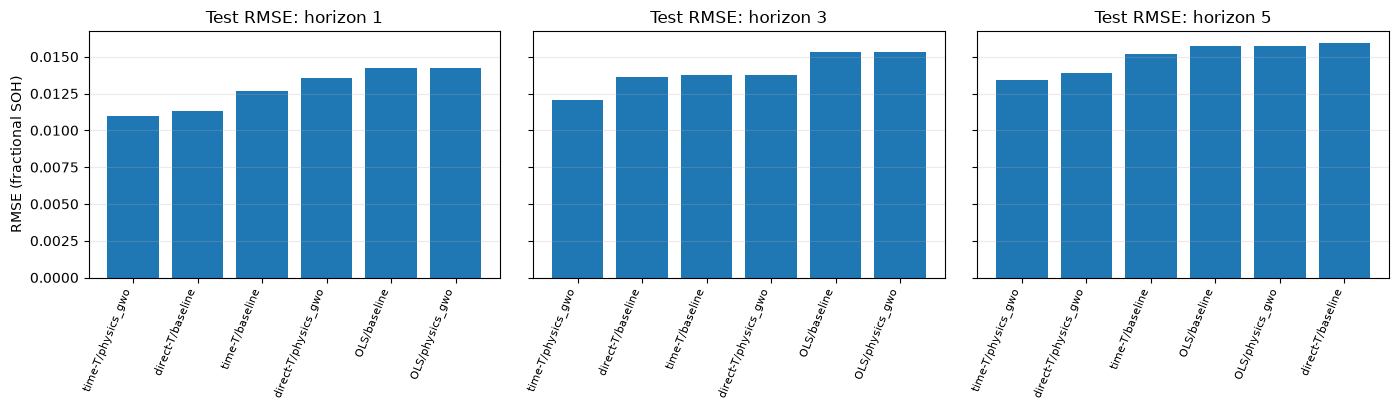

Saved baseline and physics-guided model files to: C:\Projects\Battery_Soh\pre processed ready to use data\gwo_physics_three_models\full


In [14]:
# Cell 14 — Plot model comparisons and save complete manifest
fig,axes=plt.subplots(1,3,figsize=(14,4.2),sharey=True)
for j,h in enumerate(HORIZONS):
    d=test_results[test_results.horizon==h].sort_values('RMSE')
    labels=d.model.str.replace('_transformer','-T',regex=False).str.replace('ols_last_CC_CV','OLS',regex=False)+'/'+d.variant
    axes[j].bar(range(len(d)),d.RMSE)
    axes[j].set_xticks(range(len(d)),labels,rotation=68,ha='right',fontsize=8)
    axes[j].set_title(f'Test RMSE: horizon {h}')
    axes[j].grid(axis='y',alpha=.25)
axes[0].set_ylabel('RMSE (fractional SOH)')
fig.tight_layout();fig.savefig(OUT/'test_model_comparison.png',dpi=160);plt.show()

report={'task':'next_cycle_soh_forecasting','run_mode':RUN_MODE,'dataset':str(DATA_DIR),
        'train_file':TRAIN_NAME,'validation_file':VAL_NAME,'test_file':TEST_NAME,
        'features':FEATURES,'lookback':LOOKBACK,'horizons':HORIZONS,
        'dt_scale_hours':DT_SCALE_H,'max_observed_gap_hours':MAX_OBSERVED_GAP_H,
        'soh_bounds':[SOH_LOWER,SOH_UPPER],'backbone_configs':CONFIGS,
        'gwo_lower':GWO_LOWER.tolist(),'gwo_upper':GWO_UPPER.tolist(),
        'gwo_iterations':GWO_ITERS,'gwo_population':GWO_WOLVES,
        'gwo_candidate_epochs':GWO_EPOCHS,'gwo_results':gwo_results,
        'selected_models':best_rows,
        'limitations':['No calibrated battery PDE; soft empirical priors only',
                       'No known rest inferred from timestamps',
                       'One validation and test cell; cross-battery LOBO still required',
                       'GWO may select zero weights',
                       'Prior held-out test results have already been viewed in this research']}
(OUT/'EXPERIMENT_MANIFEST.json').write_text(json.dumps(report,indent=2,default=float))
print('Saved baseline and physics-guided model files to:',OUT)


## Interpreting the experiment

**What counts as improvement?** Compare the physics-guided and unconstrained versions of the *same* backbone at the same horizon, using validation-selected configurations and untouched test evaluation. Also compare the rate of monotonic-horizon violations and out-of-range forecasts. A lower physics-violation rate **alone** is not sufficient evidence of better SOH forecasting.

**What does GWO optimize?** Only `lambda_mono` and `lambda_bound` (the two physics-loss coefficients). It does not update Transformer weights and cannot be claimed to find a globally optimal solution. The approach has already appeared in 2026 battery SOH research.

**Publication caution:** Measured capacity fluctuations can be genuine or artifacts. The prior is optional and penalized softly. Further work must use nested battery-level validation, include physically relevant raw measurements to support a true mechanistic PINN, and separately investigate whether missing history creates bias.